In [7]:
!pip install albumentations --quiet

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models, mixed_precision, Model
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, Activation, Add, 
    UpSampling2D, Concatenate, Dropout, MaxPooling2D,
    Conv2DTranspose, GlobalAveragePooling2D, Dense, Multiply
)
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import albumentations as A
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Mixed Precision 
policy = mixed_precision.Policy('mixed_float16')
mixed_precision.set_global_policy(policy)

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

ORIG_WIDTH = 4096
ORIG_HEIGHT = 256

PATCH_WIDTH = 256
PATCH_HEIGHT = 256
IMG_SHAPE = (PATCH_HEIGHT, PATCH_WIDTH, 1)
BATCH_SIZE = 8
EPOCHS = 100


PROCESSED_BASE_PATH = ""
found = False

for root, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "val" in dirs:
        PROCESSED_BASE_PATH = root
        found = True
        print(f"Dataset Path: {PROCESSED_BASE_PATH}")
        break

if not found:
    print("train folder couldn't been found, processing with default path")
    PROCESSED_BASE_PATH = "/kaggle/input/aitex-dataset/aitex_dataset_processed"

TRAIN_DIR = os.path.join(PROCESSED_BASE_PATH, "train")
VAL_DIR = os.path.join(PROCESSED_BASE_PATH, "val")

print(f"Train Path: {TRAIN_DIR}")
print(f"Validation Path: {VAL_DIR}")

# Augmentation
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.3),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.2),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=5, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.1),
    # for tiny flaws
    A.ElasticTransform(alpha=50, sigma=10, p=0.1),
    A.GridDistortion(num_steps=5, distort_limit=0.1, p=0.1),
], additional_targets={'mask': 'mask'})

def augment_fn(image, mask):
    img_np = image.numpy()
    mask_np = mask.numpy()
    
    img_np = (img_np * 255).astype(np.uint8)
    mask_np = mask_np.astype(np.float32)
    
    img_np = np.squeeze(img_np)
    mask_np = np.squeeze(mask_np)
    
    augmented = train_transform(image=img_np, mask=mask_np)
    
    aug_image = augmented['image'].astype(np.float32) / 255.0
    aug_mask = augmented['mask'].astype(np.float32)
    
    aug_image = np.expand_dims(aug_image, axis=-1)
    aug_mask = np.expand_dims(aug_mask, axis=-1)
    
    return aug_image, aug_mask

def tf_augment_wrapper(image, mask):
    aug_image, aug_mask = tf.py_function(
        func=augment_fn, 
        inp=[image, mask], 
        Tout=[tf.float32, tf.float32]
    )
    aug_image.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
    aug_mask.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
    return aug_image, aug_mask

def create_weighted_dataset(data_dir, batch_size, augment=True):
    img_folder = os.path.join(data_dir, "images")
    mask_folder = os.path.join(data_dir, "masks")
    
    image_paths = sorted([os.path.join(img_folder, f) for f in 
                         os.listdir(img_folder) if f.endswith('.png')])
    
    defect_paths = []
    normal_paths = []
    
    for img_path in image_paths:
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        
        if os.path.exists(mask_path):
            defect_paths.append(img_path)
        else:
            empty_marker = os.path.join(mask_folder, 
                                       img_filename.replace('.png', '_EMPTY_MASK_PLACEHOLDER.txt'))
            if os.path.exists(empty_marker):
                normal_paths.append(img_path)
    
    print(f"Dataset: {len(defect_paths)} Defective, {len(normal_paths)} Normal")
    
    # Make 10x more defective
    defect_multiplier = 10
    weighted_paths = defect_paths * defect_multiplier + normal_paths
    np.random.shuffle(weighted_paths)
    
    print(f"After weighting: {len(defect_paths) * defect_multiplier} defective, "
          f"{len(normal_paths)} normal example")
    
    def load_and_smart_crop(img_path_tensor):
        img_path = img_path_tensor.numpy().decode('utf-8')
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if image is None:
            return (np.zeros((PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=np.float32),
                    np.zeros((PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=np.float32))
        
        h, w = image.shape
        
        if os.path.exists(mask_path):
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask = (mask > 0).astype(np.float32)
        else:
            mask = np.zeros((h, w), dtype=np.float32)
        
        crop_size = PATCH_WIDTH
        
        if w < crop_size:
            pad_width = crop_size - w
            image = np.pad(image, ((0, 0), (0, pad_width)), mode='reflect')
            mask = np.pad(mask, ((0, 0), (0, pad_width)), mode='constant')
            w = crop_size
        
        has_defect = os.path.exists(mask_path) and np.sum(mask) > 0
        
        if has_defect:
            y_indices, x_indices = np.where(mask > 0)
            
            if len(x_indices) > 0 and np.random.rand() < 0.95:
                idx = np.random.randint(0, len(x_indices))
                center_x = x_indices[idx]
                jitter = np.random.randint(-crop_size//4, crop_size//4)
                center_x = np.clip(center_x + jitter, crop_size//2, w - crop_size//2)
                start_x = max(0, min(center_x - crop_size // 2, w - crop_size))
            else:
                start_x = np.random.randint(0, max(1, w - crop_size + 1))
        else:
            start_x = np.random.randint(0, max(1, w - crop_size + 1))
        
        img_patch = image[:, start_x:start_x + crop_size]
        mask_patch = mask[:, start_x:start_x + crop_size]
        
        if img_patch.shape != (PATCH_HEIGHT, crop_size):
            img_patch = cv2.resize(img_patch, (crop_size, PATCH_HEIGHT))
            mask_patch = cv2.resize(mask_patch, (crop_size, PATCH_HEIGHT))
        
        img_patch = np.expand_dims(img_patch, axis=-1).astype(np.float32) / 255.0
        mask_patch = np.expand_dims(mask_patch, axis=-1).astype(np.float32)
        
        return img_patch, mask_patch
    
    dataset = tf.data.Dataset.from_tensor_slices(weighted_paths)
    dataset = dataset.map(
        lambda x: tf.py_function(load_and_smart_crop, [x], [tf.float32, tf.float32]),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    
    def set_shapes(image, mask):
        image.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
        mask.set_shape((PATCH_HEIGHT, PATCH_WIDTH, 1))
        return image, mask
    
    dataset = dataset.map(set_shapes)
    
    if augment:
        dataset = dataset.map(tf_augment_wrapper, num_parallel_calls=tf.data.AUTOTUNE)
    
    dataset = dataset.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)
    
    return dataset

def create_validation_dataset(data_dir, batch_size):
    img_folder = os.path.join(data_dir, "images")
    mask_folder = os.path.join(data_dir, "masks")
    image_paths = sorted([os.path.join(img_folder, f) for f in os.listdir(img_folder) if f.endswith('.png')])
    valid_paths = []
    
    for img_path in image_paths:
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        empty_marker = os.path.join(mask_folder, img_filename.replace('.png', '_EMPTY_MASK_PLACEHOLDER.txt'))
        if os.path.exists(mask_path) or os.path.exists(empty_marker):
            valid_paths.append(img_path)
            
    def patch_generator():
        for img_path in valid_paths:
            img_filename = os.path.basename(img_path)
            mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
            image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            
            if os.path.exists(mask_path):
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                mask = (mask > 0).astype(np.float32)
                mask = np.expand_dims(mask, axis=-1)
            else:
                mask = np.zeros((ORIG_HEIGHT, ORIG_WIDTH, 1), dtype=np.float32)
            
            image = np.expand_dims(image, axis=-1).astype(np.float32) / 255.0
            
            for x in range(0, ORIG_WIDTH, PATCH_WIDTH):
                if x + PATCH_WIDTH > ORIG_WIDTH: 
                    break
                img_patch = image[:, x:x+PATCH_WIDTH, :]
                mask_patch = mask[:, x:x+PATCH_WIDTH, :]
                yield img_patch, mask_patch
    
    dataset = tf.data.Dataset.from_generator(
        patch_generator,
        output_signature=(
            tf.TensorSpec(shape=(PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(PATCH_HEIGHT, PATCH_WIDTH, 1), dtype=tf.float32)
        )
    )
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

def load_validation_arrays(data_dir):
    # load validation data as numpy arrays
    img_folder = os.path.join(data_dir, "images")
    mask_folder = os.path.join(data_dir, "masks")
    X_val_list, y_val_list = [], []
    
    image_paths = sorted([os.path.join(img_folder, f) for f in os.listdir(img_folder) if f.endswith('.png')])
    
    for img_path in image_paths:
        img_filename = os.path.basename(img_path)
        mask_path = os.path.join(mask_folder, img_filename.replace('.png', '_mask.png'))
        empty_marker = os.path.join(mask_folder, img_filename.replace('.png', '_EMPTY_MASK_PLACEHOLDER.txt'))
        
        if not (os.path.exists(mask_path) or os.path.exists(empty_marker)):
            continue
            
        image_full = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if os.path.exists(mask_path):
            mask_full = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask_full = (mask_full > 0).astype(np.float32)
        else:
            mask_full = np.zeros((ORIG_HEIGHT, ORIG_WIDTH), dtype=np.float32)
            
        for x in range(0, ORIG_WIDTH, PATCH_WIDTH):
            if x + PATCH_WIDTH > ORIG_WIDTH: 
                break
            
            img_patch = image_full[:, x:x+PATCH_WIDTH]
            mask_patch = mask_full[:, x:x+PATCH_WIDTH]
            
            if img_patch.shape == (PATCH_HEIGHT, PATCH_WIDTH):
                X_val_list.append(img_patch / 255.0)
                y_val_list.append(mask_patch)

    if len(X_val_list) == 0:
        print("Couldn't find validation data")
        return np.array([]), np.array([])

    X_val = np.expand_dims(np.array(X_val_list).astype(np.float32), axis=-1)
    y_val = np.expand_dims(np.array(y_val_list).astype(np.float32), axis=-1)
    
    print(f"Validation data has been loaded: {X_val.shape}")
    return X_val, y_val

# Loss Functions
def balanced_focal_dice_loss(y_true, y_pred, alpha=0.9, gamma=2.0, dice_weight=0.5):
    """
    Focal Loss + Dice Loss combination
    - alpha: weighting assigned to the defect class (high = more attention to the fault)
    - gamma: degree of focus on difficult examples
    """
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    # Focal Loss
    bce = -(y_true * tf.math.log(y_pred) + (1 - y_true) * tf.math.log(1 - y_pred))
    pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
    focal_weight = tf.pow(1 - pt, gamma)
    alpha_weight = tf.where(tf.equal(y_true, 1), alpha, 1 - alpha)
    focal_loss = tf.reduce_mean(alpha_weight * focal_weight * bce)
    
    # Dice Loss
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    dice = (2.0 * intersection + 1e-6) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + 1e-6)
    dice_loss = 1.0 - dice
    
    return dice_weight * dice_loss + (1 - dice_weight) * focal_loss

def tversky_loss(y_true, y_pred, alpha=0.8, beta=0.2, smooth=1e-6):
    """
    Tversky Loss - It gives more weight to recall
    alpha > beta: False negatives incur more penalties (missing faults).
    """
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    true_pos = tf.reduce_sum(y_true_f * y_pred_f)
    false_neg = tf.reduce_sum(y_true_f * (1 - y_pred_f))
    false_pos = tf.reduce_sum((1 - y_true_f) * y_pred_f)
    
    tversky = (true_pos + smooth) / (true_pos + alpha * false_neg + beta * false_pos + smooth)
    
    return 1 - tversky

def combined_loss(y_true, y_pred):
    """Focal Dice + Tversky Loss Combination"""
    focal_dice = balanced_focal_dice_loss(y_true, y_pred)
    tversky = tversky_loss(y_true, y_pred)
    return 0.5 * focal_dice + 0.5 * tversky

# Metrics
def dice_coefficient(y_true, y_pred, threshold=0.3, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def recall_metric(y_true, y_pred, threshold=0.3):
    # How many defects were found?
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    actual_positives = tf.reduce_sum(y_true_f)
    
    return true_positives / (actual_positives + 1e-7)

def precision_metric(y_true, y_pred, threshold=0.5):
    # How accurate are the predictions?
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    
    return true_positives / (predicted_positives + 1e-7)

def iou_metric(y_true, y_pred, threshold=0.3, smooth=1e-6):
    # IoU (Intersection over Union)
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred > threshold, tf.float32)
    
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    
    return (intersection + smooth) / (union + smooth)


def find_optimal_threshold(model, X_val, y_val):
    """Find threshold that maximizes F1 score"""
    y_pred = model.predict(X_val, verbose=1)
    best_f1 = 0
    best_thresh = 0.5
    best_precision = 0
    best_recall = 0
    
    print("\nThreshold Analysis:")
    
    for thresh in np.arange(0.1, 0.9, 0.05):
        y_pred_binary = (y_pred > thresh).astype(np.float32)
        
        tp = np.sum(y_val * y_pred_binary)
        fp = np.sum((1 - y_val) * y_pred_binary)
        fn = np.sum(y_val * (1 - y_pred_binary))
        
        precision = tp / (tp + fp + 1e-7)
        recall = tp / (tp + fn + 1e-7)
        f1 = 2 * precision * recall / (precision + recall + 1e-7)
        
        print(f"Thresh: {thresh:.2f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
        
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = thresh
            best_precision = precision
            best_recall = recall
    
    print(f"Optimal threshold: {best_thresh:.2f}")
    print(f"Precision: {best_precision:.4f}, Recall: {best_recall:.4f}, F1: {best_f1:.4f}")
    
    return best_thresh
    
# U-NET 
def attention_gate(g, x, filters):
    g1 = Conv2D(filters, 1, padding='same')(g)
    x1 = Conv2D(filters, 1, padding='same')(x)
    psi = Activation('relu')(Add()([g1, x1]))
    psi = Conv2D(1, 1, padding='same')(psi)
    psi = Activation('sigmoid')(psi)
    return Multiply()([x, psi])

def conv_block(x, filters, kernel_size=3, use_batch_norm=True):
    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_batch_norm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_batch_norm:
        x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    return x

def build_attention_unet(input_shape=IMG_SHAPE, name="Attention_UNet"):
    inputs = Input(input_shape)
    
    # ENCODER
    # Level 1
    c1 = conv_block(inputs, 32)
    r1 = Conv2D(32, 1, padding='same')(inputs)
    c1 = Add()([c1, r1])
    p1 = MaxPooling2D(2)(c1)
    p1 = Dropout(0.1)(p1)
    
    # Level 2
    c2 = conv_block(p1, 64)
    r2 = Conv2D(64, 1, padding='same')(p1)
    c2 = Add()([c2, r2])
    p2 = MaxPooling2D(2)(c2)
    p2 = Dropout(0.1)(p2)
    
    # Level 3
    c3 = conv_block(p2, 128)
    r3 = Conv2D(128, 1, padding='same')(p2)
    c3 = Add()([c3, r3])
    p3 = MaxPooling2D(2)(c3)
    p3 = Dropout(0.2)(p3)
    
    # Level 4
    c4 = conv_block(p3, 256)
    r4 = Conv2D(256, 1, padding='same')(p3)
    c4 = Add()([c4, r4])
    p4 = MaxPooling2D(2)(c4)
    p4 = Dropout(0.2)(p4)
    
    # BOTTLENECK (ASPP) 
    b1 = Conv2D(512, 3, activation='relu', padding='same', dilation_rate=1)(p4)
    b2 = Conv2D(512, 3, activation='relu', padding='same', dilation_rate=2)(p4)
    b3 = Conv2D(512, 3, activation='relu', padding='same', dilation_rate=4)(p4)
    bottleneck = Concatenate()([b1, b2, b3])
    bottleneck = Conv2D(512, 1, activation='relu', padding='same')(bottleneck)
    bottleneck = BatchNormalization()(bottleneck)
    bottleneck = Dropout(0.3)(bottleneck)
    
    # DECODER 
    # Level 4
    u4 = Conv2DTranspose(256, 2, strides=2, padding='same')(bottleneck)
    c4_att = attention_gate(u4, c4, 256)
    u4 = Concatenate()([u4, c4_att])
    d4 = conv_block(u4, 256)
    d4 = Dropout(0.2)(d4)
    
    # Level 3
    u3 = Conv2DTranspose(128, 2, strides=2, padding='same')(d4)
    c3_att = attention_gate(u3, c3, 128)
    u3 = Concatenate()([u3, c3_att])
    d3 = conv_block(u3, 128)
    d3 = Dropout(0.1)(d3)
    
    # Level 2
    u2 = Conv2DTranspose(64, 2, strides=2, padding='same')(d3)
    c2_att = attention_gate(u2, c2, 64)
    u2 = Concatenate()([u2, c2_att])
    d2 = conv_block(u2, 64)
    d2 = Dropout(0.1)(d2)
    
    # Level 1
    u1 = Conv2DTranspose(32, 2, strides=2, padding='same')(d2)
    c1_att = attention_gate(u1, c1, 32)
    u1 = Concatenate()([u1, c1_att])
    d1 = conv_block(u1, 32)
    
    # Output
    outputs = Conv2D(1, 1, activation='sigmoid', dtype='float32')(d1)
    
    model = Model(inputs=inputs, outputs=outputs, name=name)
    return model

# HRNet
def basic_block(x, filters, stride=1):
    shortcut = x
    
    x = Conv2D(filters, 3, strides=stride, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    x = Conv2D(filters, 3, padding='same')(x)
    x = BatchNormalization()(x)
    
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, 1, strides=stride, padding='same')(shortcut)
        shortcut = BatchNormalization()(shortcut)
    
    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    
    return x

def make_layer(x, filters, num_blocks):
    # A layer consisting of multiple basic blocks
    for _ in range(num_blocks):
        x = basic_block(x, filters)
    return x

def transition_layer(x, out_filters):
    x = Conv2D(out_filters, 3, strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    return x

def fuse_layers(branches, num_branches, num_filters):
    """
    HRNet's core feature: Combines different resolutions
    - High-resolution information is preserved
    - Semantic information is extracted from low-resolution data
    """
    fused = []
    
    for i in range(num_branches):
        fused_branch = None
        
        for j in range(num_branches):
            if j == i:
                # Same resolution 
                branch = branches[j]
            elif j < i:
                # From high resolution to low resolution - downsample
                branch = branches[j]
                for k in range(i - j):
                    branch = Conv2D(num_filters[i], 3, strides=2, padding='same')(branch)
                    branch = BatchNormalization()(branch)
                    if k < i - j - 1:
                        branch = Activation('relu')(branch)
            else:
                # From low resolution to high resolution - upsample
                branch = branches[j]
                branch = Conv2D(num_filters[i], 1, padding='same')(branch)
                branch = BatchNormalization()(branch)
                scale = 2 ** (j - i)
                branch = UpSampling2D(size=(scale, scale), interpolation='bilinear')(branch)
            
            if fused_branch is None:
                fused_branch = branch
            else:
                fused_branch = Add()([fused_branch, branch])
        
        fused_branch = Activation('relu')(fused_branch)
        fused.append(fused_branch)
    
    return fused

def build_hrnet(input_shape=IMG_SHAPE, name="HRNet"):
    """
    HRNet (High-Resolution Network)
    
    Features:
    - It preserves high resolution from start to finish.
    - Parallel multi-resolution streams
    - Continuous information exchange (fusion)
    - Very effective for small objects
    """
    inputs = Input(input_shape)
    
    # STEM 
    x = Conv2D(64, 3, strides=2, padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    x = Conv2D(64, 3, strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # STAGE 1
    x = make_layer(x, 64, num_blocks=4)
    
    # STAGE 2
    # Branch 1: High resolution (64x64)
    branch1 = Conv2D(32, 3, padding='same')(x)
    branch1 = BatchNormalization()(branch1)
    branch1 = Activation('relu')(branch1)
    
    # Branch 2: Middle resolution (32x32)
    branch2 = transition_layer(x, 64)
    
    # Stage 2 processes
    branch1 = make_layer(branch1, 32, num_blocks=4)
    branch2 = make_layer(branch2, 64, num_blocks=4)
    
    # Fusion
    branches = [branch1, branch2]
    branches = fuse_layers(branches, 2, [32, 64])
    
    # STAGE 3
    branch1, branch2 = branches[0], branches[1]
    
    # Add new branch 3 (16x16)
    branch3 = transition_layer(branch2, 128)
    
    # Stage 3 processes
    branch1 = make_layer(branch1, 32, num_blocks=4)
    branch2 = make_layer(branch2, 64, num_blocks=4)
    branch3 = make_layer(branch3, 128, num_blocks=4)
    
    # Fusion
    branches = [branch1, branch2, branch3]
    branches = fuse_layers(branches, 3, [32, 64, 128])
    
    # STAGE 4
    branch1, branch2, branch3 = branches[0], branches[1], branches[2]
    
    # Add new branch 4  (8x8)
    branch4 = transition_layer(branch3, 256)
    
    # Stage 4 processes
    branch1 = make_layer(branch1, 32, num_blocks=4)
    branch2 = make_layer(branch2, 64, num_blocks=4)
    branch3 = make_layer(branch3, 128, num_blocks=4)
    branch4 = make_layer(branch4, 256, num_blocks=4)
    
    # Final Fusion
    branches = [branch1, branch2, branch3, branch4]
    branches = fuse_layers(branches, 4, [32, 64, 128, 256])
    
    # SEGMENTATION HEAD 
    # Bring all branches to high resolution
    upsampled = []
    
    # Branch 1 (64x64) - already high resolution
    upsampled.append(branches[0])
    
    # Branch 2 (32x32) -> 64x64
    up2 = UpSampling2D(size=(2, 2), interpolation='bilinear')(branches[1])
    up2 = Conv2D(32, 1, padding='same')(up2)
    upsampled.append(up2)
    
    # Branch 3 (16x16) -> 64x64
    up3 = UpSampling2D(size=(4, 4), interpolation='bilinear')(branches[2])
    up3 = Conv2D(32, 1, padding='same')(up3)
    upsampled.append(up3)
    
    # Branch 4 (8x8) -> 64x64
    up4 = UpSampling2D(size=(8, 8), interpolation='bilinear')(branches[3])
    up4 = Conv2D(32, 1, padding='same')(up4)
    upsampled.append(up4)
    
    # Merge
    x = Concatenate()(upsampled)
    x = Conv2D(128, 3, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Dropout(0.2)(x)
    
    # Return to original size (64x64 -> 256x256)
    x = UpSampling2D(size=(4, 4), interpolation='bilinear')(x)
    
    # Final convolutions
    x = Conv2D(64, 3, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    x = Conv2D(32, 3, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Output
    outputs = Conv2D(1, 1, activation='sigmoid', dtype='float32')(x)
    
    model = Model(inputs=inputs, outputs=outputs, name=name)
    return model

# Create Datasets

train_dataset = create_weighted_dataset(TRAIN_DIR, BATCH_SIZE, augment=True)
val_dataset = create_validation_dataset(VAL_DIR, BATCH_SIZE)

# Validation arrays
X_val, y_val = load_validation_arrays(VAL_DIR)

print(f"\nDatasets are ready")

TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Dataset Path: /kaggle/input/aitex-dataset/aitex_dataset_processed
Train Path: /kaggle/input/aitex-dataset/aitex_dataset_processed/train
Validation Path: /kaggle/input/aitex-dataset/aitex_dataset_processed/val
Dataset: 82 Defective, 112 Normal
After weighting: 820 defective, 112 normal example
Validation data has been loaded: (784, 256, 256, 1)

Datasets are ready


In [9]:
# Create models
# U-Net modeli
unet_model = build_attention_unet(IMG_SHAPE, name="Attention_UNet")
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[
        dice_coefficient,
        recall_metric,
        precision_metric,
        iou_metric
    ]
)

print(f"\nAttention U-Net Parameters: {unet_model.count_params():,}")

# HRNet model
hrnet_model = build_hrnet(IMG_SHAPE, name="HRNet")
hrnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[
        dice_coefficient,
        recall_metric,
        precision_metric,
        iou_metric
    ]
)

print(f"HRNet Parametreleri: {hrnet_model.count_params():,}")


print("\nATTENTION U-NET MODEL SUMMARY")
unet_model.summary()

print("\nHRNET MODEL SUMMARY")
hrnet_model.summary()

# Callbacks
def get_callbacks(model_name):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_dice_coefficient',
            patience=15,
            mode='max',
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_dice_coefficient',
            factor=0.5,
            patience=7,
            min_lr=1e-7,
            mode='max',
            verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            f'{model_name}_best.keras',
            monitor='val_dice_coefficient',
            mode='max',
            save_best_only=True,
            verbose=1
        ),
        tf.keras.callbacks.CSVLogger(f'{model_name}_training_log.csv')
    ]
    
    return callbacks

# U-Net Training
print("Starting to train U-Net")

unet_callbacks = get_callbacks("attention_unet")

unet_history = unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=unet_callbacks,
    verbose=1
)

print("\nU-Net training has been done")


Attention U-Net Parameters: 8,775,749
HRNet Parametreleri: 12,192,961

ATTENTION U-NET MODEL SUMMARY


Model: "Attention_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_701 (Conv2D) │ (None, 256, 256,  │        320 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_701[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_587      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_702 (Conv2D) │ (None, 256, 256,  │      9,248 │ activation_587[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_702[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_588      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_703 (Conv2D) │ (None, 256, 256,  │         64 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_324 (Add)       │ (None, 256, 256,  │          0 │ activation_588[0… │
│                     │ 32)               │            │ conv2d_703[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 128, 128,  │          0 │ add_324[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_29          │ (None, 128, 128,  │          0 │ max_pooling2d_12… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_704 (Conv2D) │ (None, 128, 128,  │     18,496 │ dropout_29[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_704[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_589      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_705 (Conv2D) │ (None, 128, 128,  │     36,928 │ activation_589[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_705[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_590      │ (None, 128, 128,  │          0 │ batch_normalizat

 Total params: 8,775,749 (33.48 MB)

 Trainable params: 8,770,885 (33.46 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_738 (Conv2D) │ (None, 128, 128,  │        640 │ input_layer_9[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_738[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_611      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_739 (Conv2D) │ (None, 64, 64,    │     36,928 │ activation_611[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_739[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_612      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_740 (Conv2D) │ (None, 64, 64,    │     36,928 │ activation_612[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_740[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_613      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_741 (Conv2D) │ (None, 64, 64,    │     36,928 │ activation_613[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_741[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_332 (Add)       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ activation_612[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_614      │ (None, 64, 64,    │          0 │ add_332[0][0]     │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_742 (Conv2D) │ (None, 64, 64,    │     36,928 │ activation_614[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_742[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_615      │ (None, 64, 64,    │          0 │ batch_normalizat

 Total params: 12,192,961 (46.51 MB)

 Trainable params: 12,171,457 (46.43 MB)

 Non-trainable params: 21,504 (84.00 KB)

Starting to train U-Net
Epoch 1/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - dice_coefficient: 0.0155 - iou_metric: 0.0079 - loss: 0.7377 - precision_metric: 0.0083 - recall_metric: 0.9881
Epoch 1: val_dice_coefficient improved from -inf to 0.00782, saving model to attention_unet_best.keras
117/117 ━━━━━━━━━━━━━━━━━━━━ 87s 328ms/step - dice_coefficient: 0.0155 - iou_metric: 0.0079 - loss: 0.7377 - precision_metric: 0.0083 - recall_metric: 0.9881 - val_dice_coefficient: 0.0078 - val_iou_metric: 0.0048 - val_loss: 0.7481 - val_precision_metric: 0.0061 - val_recall_metric: 0.2143 - learning_rate: 1.0000e-04
Epoch 2/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - dice_coefficient: 0.0185 - iou_metric: 0.0095 - loss: 0.7248 - precision_metric: 0.0181 - recall_metric: 0.9623
Epoch 2: val_dice_coefficient improved from 0.00782 to 0.00784, saving model to attention_unet_best.keras
117/117 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - dice_coefficient: 0.0186 - iou_metric: 0.0095 - loss: 0.7247 - p

Switching to float32 for HRNet training...
HRNet Parameters: 12,192,961
Dataset: 82 Defective, 112 Normal
After weighting: 820 defective, 112 normal example
Epoch 1/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - dice_coefficient: 0.0183 - iou_metric: 0.0093 - loss: 0.7330 - precision_metric: 0.0111 - recall_metric: 0.9805
Epoch 1: val_dice_coefficient improved from -inf to 0.00642, saving model to hrnet_best.keras
117/117 ━━━━━━━━━━━━━━━━━━━━ 222s 854ms/step - dice_coefficient: 0.0183 - iou_metric: 0.0093 - loss: 0.7329 - precision_metric: 0.0111 - recall_metric: 0.9805 - val_dice_coefficient: 0.0064 - val_iou_metric: 0.0038 - val_loss: 0.7468 - val_precision_metric: 0.0000e+00 - val_recall_metric: 0.1169 - learning_rate: 1.0000e-04
Epoch 2/100
117/117 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - dice_coefficient: 0.0295 - iou_metric: 0.0154 - loss: 0.7138 - precision_metric: 0.0296 - recall_metric: 0.8468
Epoch 2: val_dice_coefficient improved from 0.00642 to 0.00726, saving model to hrnet_

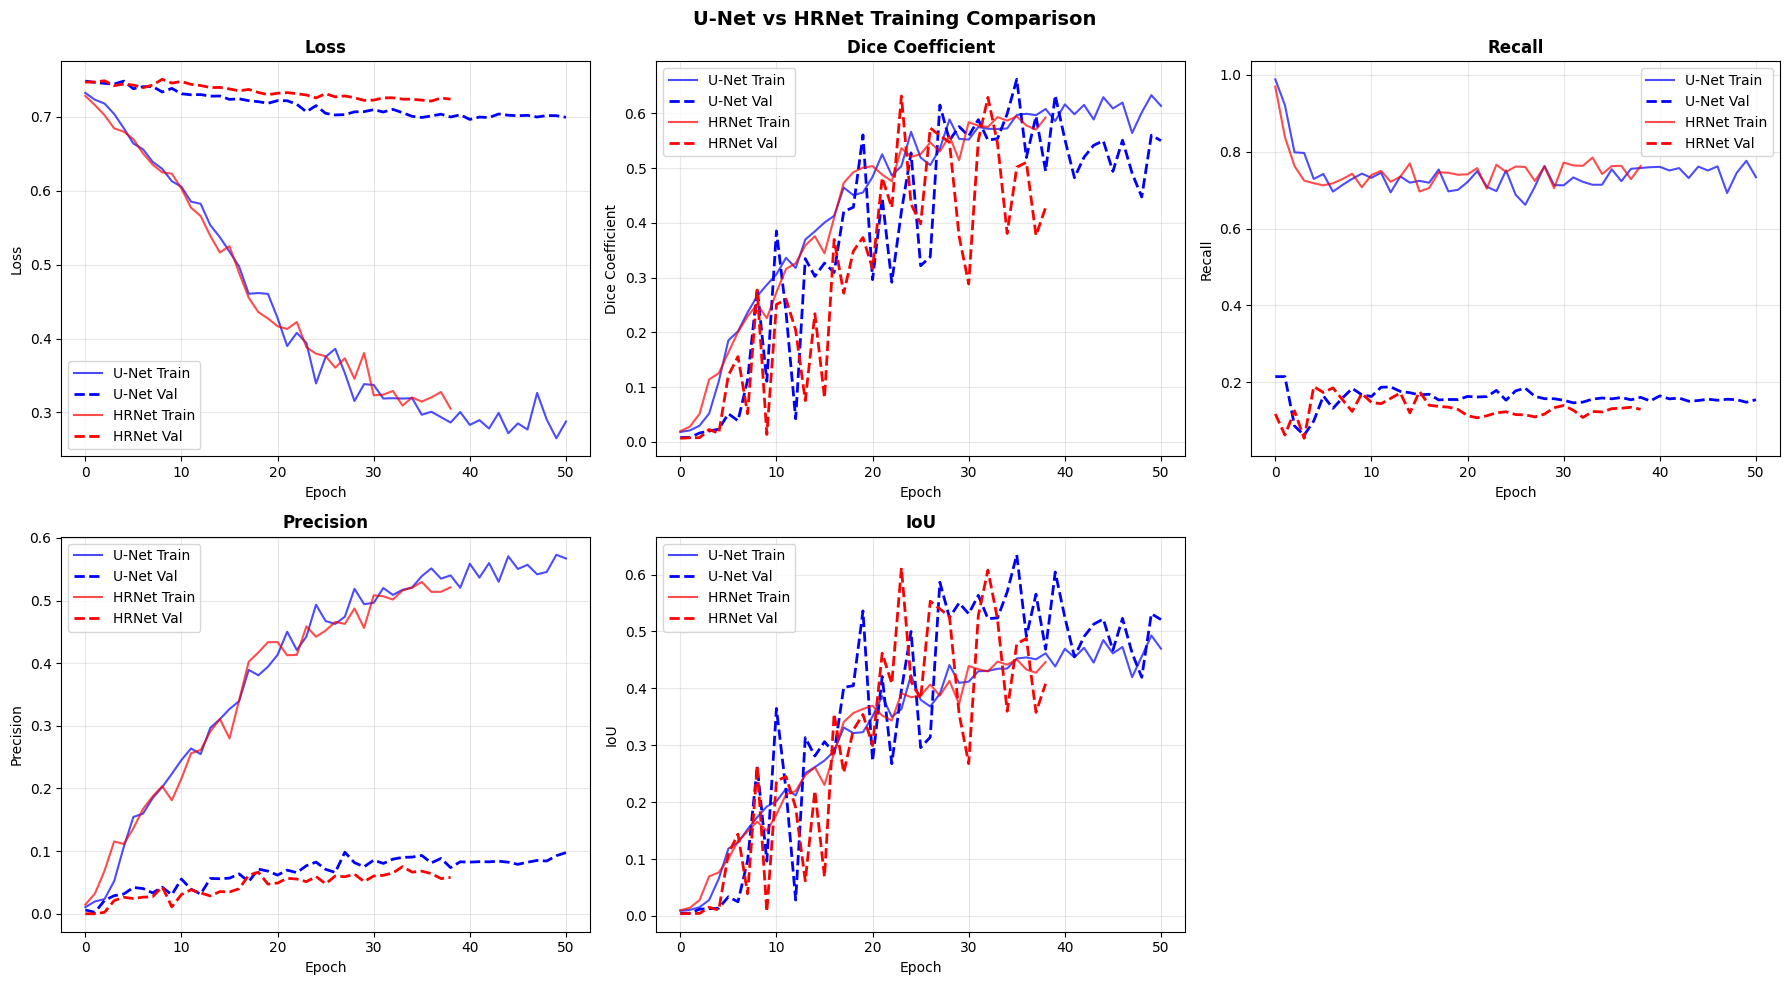


Results of Unet:
   loss: 0.6990
   compile_metrics: 0.6622

Results of HRNet:
   loss: 0.7294
   compile_metrics: 0.6316
Metrik               U-Net           HRNet           Kazanan        
Loss                 0.6990          0.7294          U-Net positive 
Dice                 0.6622          0.6316          U-Net positive 
Recall               0.1564          0.1199          U-Net positive 
Precision            0.0931          0.0512          U-Net positive 
IoU                  0.6349          0.6118          U-Net positive 

Saved: prediction_comparison.png


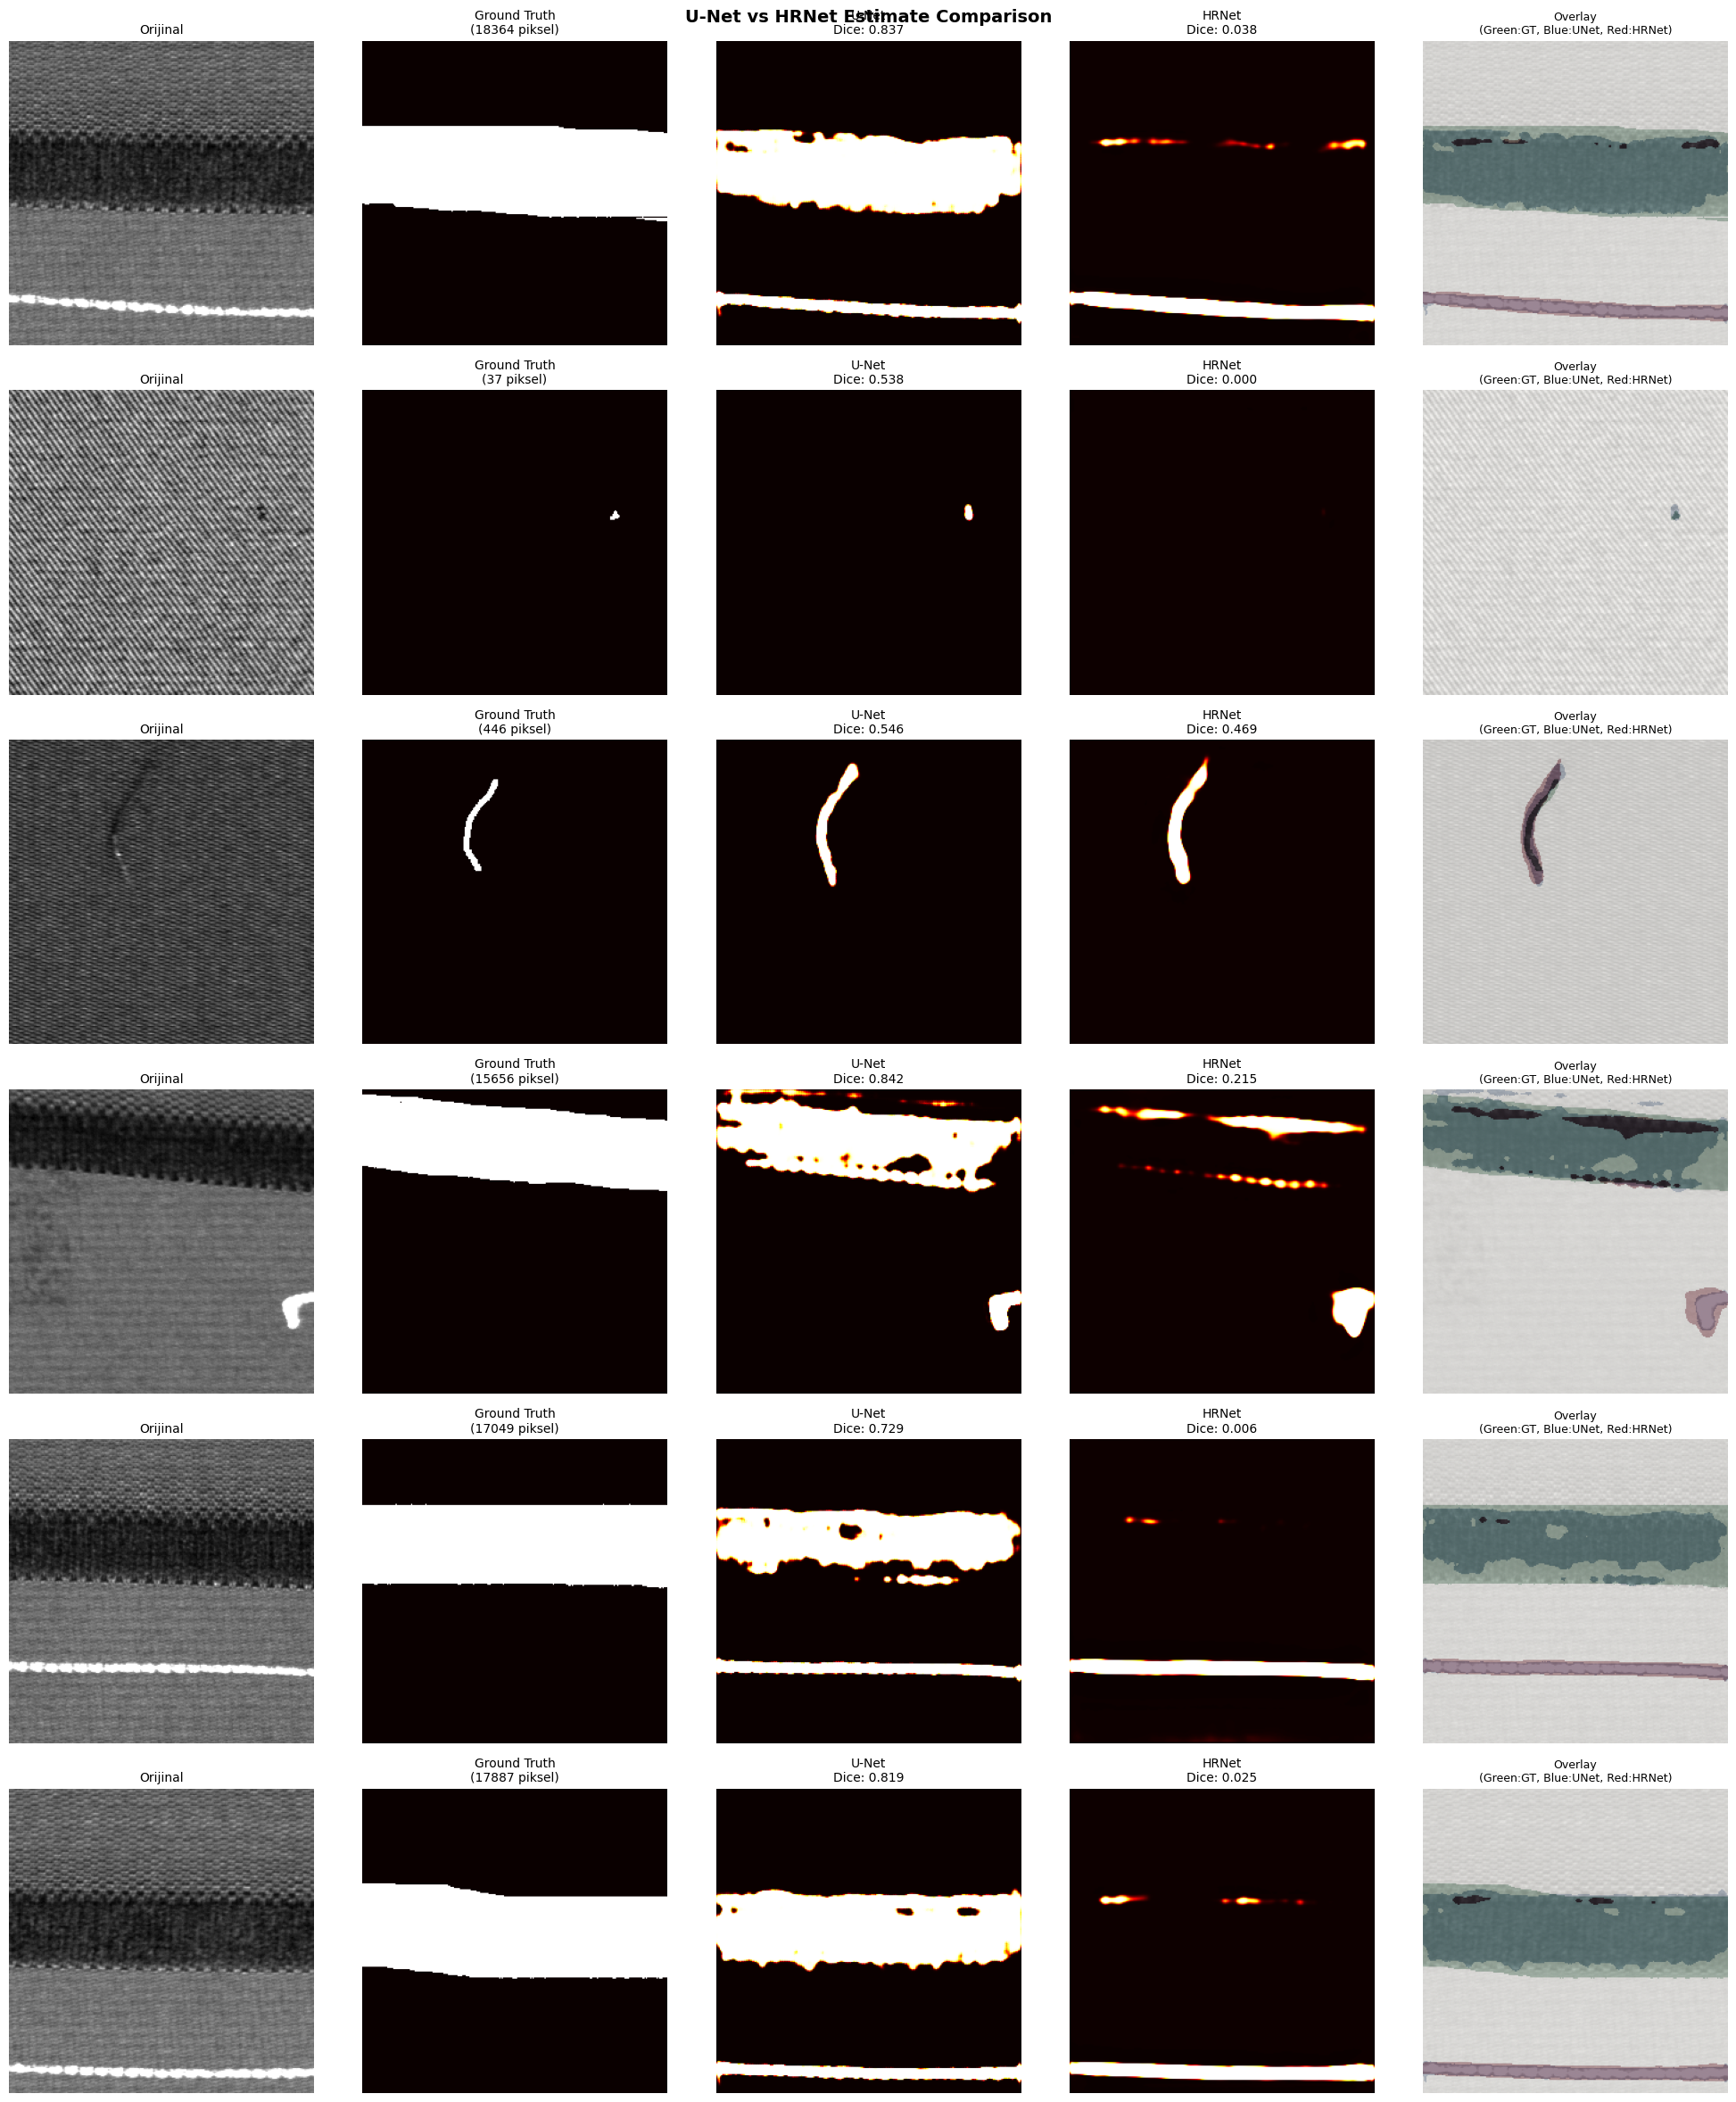


Save: heatmap_comparison.png


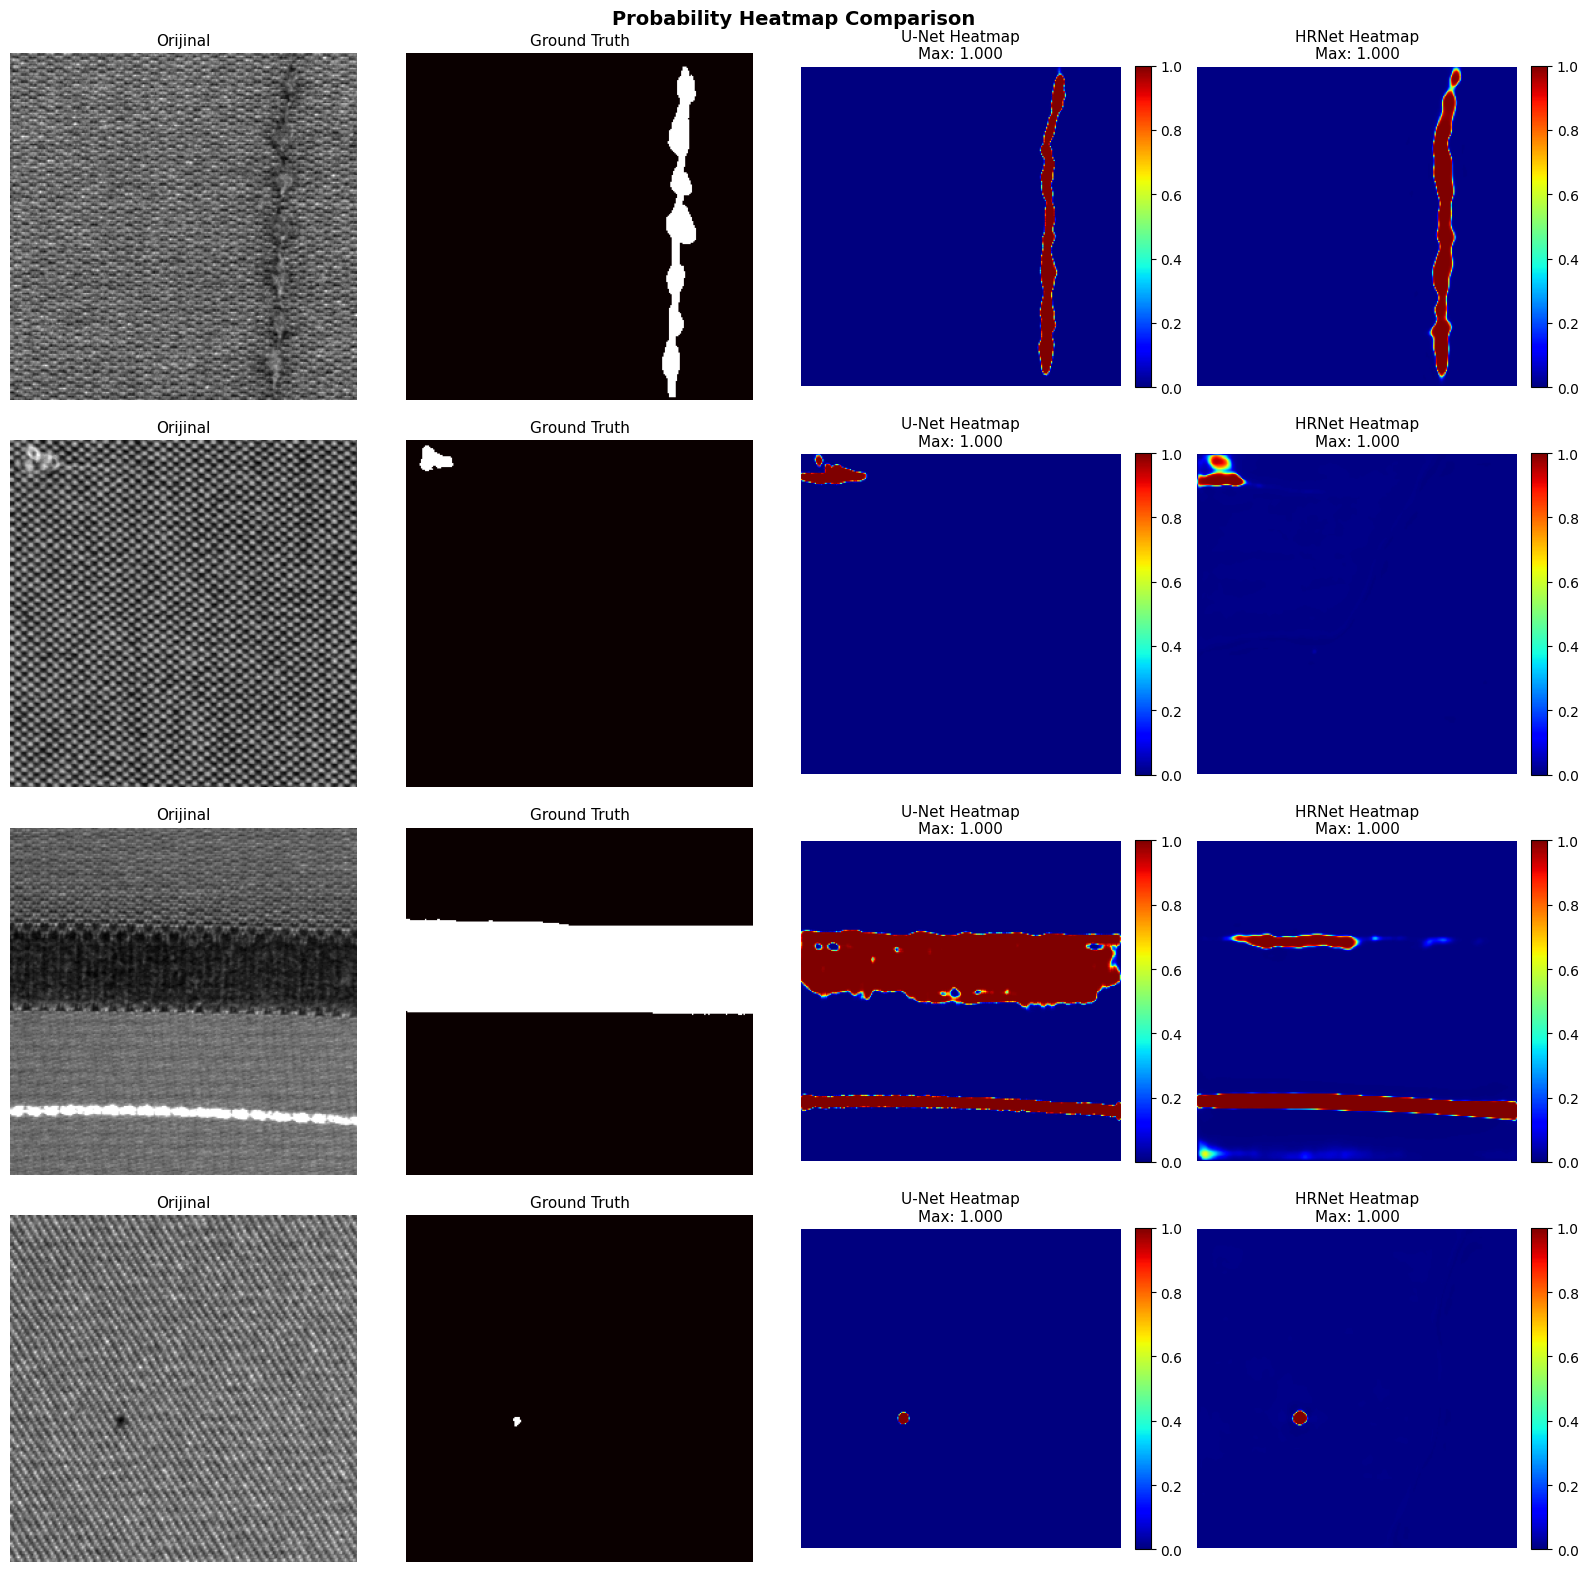


Final Results After Post-Processing
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 330ms/step

U-Net Results (Post-Processing):
   Threshold 0.2: Dice=0.7604, Recall=0.7400, Precision=0.7820, IoU=0.6134
   Threshold 0.3: Dice=0.7586, Recall=0.7345, Precision=0.7843, IoU=0.6111
   Threshold 0.4: Dice=0.7574, Recall=0.7304, Precision=0.7865, IoU=0.6096
   Threshold 0.5: Dice=0.7562, Recall=0.7266, Precision=0.7884, IoU=0.6080

HRNet Results (with Post-Processing):
   Threshold 0.2: Dice=0.1000, Recall=0.0692, Precision=0.1803, IoU=0.0526
   Threshold 0.3: Dice=0.0942, Recall=0.0642, Precision=0.1763, IoU=0.0494
   Threshold 0.4: Dice=0.0895, Recall=0.0604, Precision=0.1723, IoU=0.0468
   Threshold 0.5: Dice=0.0860, Recall=0.0576, Precision=0.1694, IoU=0.0449

U-Net Best Parameters:
   Threshold: 0.1
   Min Size: 30
   Dice: 0.7628
   Recall: 0.7486
   Precision: 0.7775
   IoU: 0.6165

HRNet Best Parameters:
   Threshold: 0.1
   Min Size: 10
   Dice: 0.1110
   Reca

In [10]:
# Reset mixed precision policy to float32 for HRNet
print("Switching to float32 for HRNet training...")
mixed_precision.set_global_policy('float32')

# Rebuild and recompile HRNet model
hrnet_model = build_hrnet(IMG_SHAPE, name="HRNet")
hrnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[
        dice_coefficient,
        recall_metric,
        precision_metric,
        iou_metric
    ]
)
print(f"HRNet Parameters: {hrnet_model.count_params():,}")

# HRNet Training
# Create datasets again (shuffle)
train_dataset = create_weighted_dataset(TRAIN_DIR, BATCH_SIZE, augment=True)
val_dataset = create_validation_dataset(VAL_DIR, BATCH_SIZE)

hrnet_callbacks = get_callbacks("hrnet")

hrnet_history = hrnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=hrnet_callbacks,
    verbose=1
)

print("\nHRNet training has been done")

print("U-Net Threshold Analysis:")
optimal_thresh_unet = find_optimal_threshold(unet_model, X_val, y_val)
print("HRNet Threshold Analysis:")
optimal_thresh_hrnet = find_optimal_threshold(hrnet_model, X_val, y_val)

# Comparison
def plot_training_comparison(unet_history, hrnet_history):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    metrics = ['loss', 'dice_coefficient', 'recall_metric', 
               'precision_metric', 'iou_metric']
    titles = ['Loss', 'Dice Coefficient', 'Recall', 'Precision', 'IoU']
    
    for idx, (metric, title) in enumerate(zip(metrics, titles)):
        row = idx // 3
        col = idx % 3
        ax = axes[row, col]
        
        # U-Net
        if metric in unet_history.history:
            ax.plot(unet_history.history[metric], 'b-', label='U-Net Train', alpha=0.7)
            ax.plot(unet_history.history[f'val_{metric}'], 'b--', label='U-Net Val', linewidth=2)
        
        # HRNet
        if metric in hrnet_history.history:
            ax.plot(hrnet_history.history[metric], 'r-', label='HRNet Train', alpha=0.7)
            ax.plot(hrnet_history.history[f'val_{metric}'], 'r--', label='HRNet Val', linewidth=2)
        
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(title)
        ax.legend(loc='best')
        ax.grid(True, alpha=0.3)
    
    # Hide the last subplot (There are 6 subplots for 5 metrics)
    axes[1, 2].axis('off')
    
    plt.suptitle('U-Net vs HRNet Training Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('training_comparison.png', dpi=300, bbox_inches='tight')
    print("\nSaved: training_comparison.png")
    plt.show()

plot_training_comparison(unet_history, hrnet_history)

# Evaluation of Models

# Create validation dataset
val_dataset = create_validation_dataset(VAL_DIR, BATCH_SIZE)

# U-Net Evaluation
print("\nResults of Unet:")
unet_results = unet_model.evaluate(val_dataset, verbose=0)
for name, value in zip(unet_model.metrics_names, unet_results):
    print(f"   {name}: {value:.4f}")

# HRNet Evaluation
val_dataset = create_validation_dataset(VAL_DIR, BATCH_SIZE)
print("\nResults of HRNet:")
hrnet_results = hrnet_model.evaluate(val_dataset, verbose=0)
for name, value in zip(hrnet_model.metrics_names, hrnet_results):
    print(f"   {name}: {value:.4f}")

# Comparison Table
print(f"{'Metrik':<20} {'U-Net':<15} {'HRNet':<15} {'Kazanan':<15}")

metric_names = ['Loss', 'Dice', 'Recall', 'Precision', 'IoU']
for i, name in enumerate(metric_names):
    unet_val = unet_results[i]
    hrnet_val = hrnet_results[i]
    
    if name == 'Loss':
        winner = "U-Net positive" if unet_val < hrnet_val else "HRNet negative"
    else:
        winner = "U-Net positive" if unet_val > hrnet_val else "HRNet negative"
    
    print(f"{name:<20} {unet_val:<15.4f} {hrnet_val:<15.4f} {winner:<15}")

# Visualization
def visualize_predictions_comparison(X_val, y_val, unet_model, hrnet_model, num_samples=6):
    # Find defective examples
    defect_indices = [i for i in range(len(y_val)) if np.sum(y_val[i]) > 0]
    
    if len(defect_indices) == 0:
        print("Couldn't find any defective examples")
        return
    
    # Choose random examples
    sample_indices = np.random.choice(defect_indices, 
                                      min(num_samples, len(defect_indices)), 
                                      replace=False)
    
    fig, axes = plt.subplots(num_samples, 5, figsize=(20, 4*num_samples))
    
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, idx in enumerate(sample_indices):
        img = X_val[idx:idx+1]
        gt = y_val[idx].squeeze()
        
        # Predictions
        unet_pred = unet_model.predict(img, verbose=0).squeeze()
        hrnet_pred = hrnet_model.predict(img, verbose=0).squeeze()
        
        # Original Image
        axes[i, 0].imshow(img.squeeze(), cmap='gray')
        axes[i, 0].set_title('Orijinal', fontsize=10)
        axes[i, 0].axis('off')
        
        # Ground Truth
        axes[i, 1].imshow(gt, cmap='hot')
        axes[i, 1].set_title(f'Ground Truth\n({int(np.sum(gt))} piksel)', fontsize=10)
        axes[i, 1].axis('off')
        
        # Prediction of U-Net
        unet_dice = 2 * np.sum(gt * (unet_pred > 0.3)) / (np.sum(gt) + np.sum(unet_pred > 0.3) + 1e-7)
        axes[i, 2].imshow(unet_pred, cmap='hot', vmin=0, vmax=1)
        axes[i, 2].set_title(f'U-Net\nDice: {unet_dice:.3f}', fontsize=10)
        axes[i, 2].axis('off')
        
        # Prediction of HRNet 
        hrnet_dice = 2 * np.sum(gt * (hrnet_pred > 0.3)) / (np.sum(gt) + np.sum(hrnet_pred > 0.3) + 1e-7)
        axes[i, 3].imshow(hrnet_pred, cmap='hot', vmin=0, vmax=1)
        axes[i, 3].set_title(f'HRNet\nDice: {hrnet_dice:.3f}', fontsize=10)
        axes[i, 3].axis('off')
        
        # Overlay Comparison
        axes[i, 4].imshow(img.squeeze(), cmap='gray')
        axes[i, 4].imshow(gt, cmap='Greens', alpha=0.5, vmin=0, vmax=1)  # GT yeşil
        axes[i, 4].imshow(unet_pred > 0.3, cmap='Blues', alpha=0.3)  # U-Net mavi
        axes[i, 4].imshow(hrnet_pred > 0.3, cmap='Reds', alpha=0.3)  # HRNet kırmızı
        axes[i, 4].set_title('Overlay\n(Green:GT, Blue:UNet, Red:HRNet)', fontsize=9)
        axes[i, 4].axis('off')
    
    plt.suptitle('U-Net vs HRNet Estimate Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('prediction_comparison.png', dpi=300, bbox_inches='tight')
    print("\nSaved: prediction_comparison.png")
    plt.show()

# Visualize
visualize_predictions_comparison(X_val, y_val, unet_model, hrnet_model, num_samples=6)

# Visualization of Heatmap
def visualize_heatmaps(X_val, y_val, unet_model, hrnet_model, num_samples=4):
    defect_indices = [i for i in range(len(y_val)) if np.sum(y_val[i]) > 0]
    sample_indices = np.random.choice(defect_indices, 
                                      min(num_samples, len(defect_indices)), 
                                      replace=False)
    
    fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4*num_samples))
    
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, idx in enumerate(sample_indices):
        img = X_val[idx:idx+1]
        gt = y_val[idx].squeeze()
        
        unet_pred = unet_model.predict(img, verbose=0).squeeze()
        hrnet_pred = hrnet_model.predict(img, verbose=0).squeeze()
        
        # Original
        axes[i, 0].imshow(img.squeeze(), cmap='gray')
        axes[i, 0].set_title('Orijinal', fontsize=11)
        axes[i, 0].axis('off')
        
        # Ground Truth
        axes[i, 1].imshow(gt, cmap='hot')
        axes[i, 1].set_title('Ground Truth', fontsize=11)
        axes[i, 1].axis('off')
        
        # U-Net Heatmap
        im2 = axes[i, 2].imshow(unet_pred, cmap='jet', vmin=0, vmax=1)
        axes[i, 2].set_title(f'U-Net Heatmap\nMax: {unet_pred.max():.3f}', fontsize=11)
        axes[i, 2].axis('off')
        plt.colorbar(im2, ax=axes[i, 2], fraction=0.046, pad=0.04)
        
        # HRNet Heatmap
        im3 = axes[i, 3].imshow(hrnet_pred, cmap='jet', vmin=0, vmax=1)
        axes[i, 3].set_title(f'HRNet Heatmap\nMax: {hrnet_pred.max():.3f}', fontsize=11)
        axes[i, 3].axis('off')
        plt.colorbar(im3, ax=axes[i, 3], fraction=0.046, pad=0.04)
    
    plt.suptitle('Probability Heatmap Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('heatmap_comparison.png', dpi=300, bbox_inches='tight')
    print("\nSave: heatmap_comparison.png")
    plt.show()

visualize_heatmaps(X_val, y_val, unet_model, hrnet_model, num_samples=4)

# Post-Processing ve Final Results
from scipy.ndimage import label, binary_opening, binary_closing, binary_fill_holes

def advanced_postprocessing(binary_mask, min_defect_size=30, fill_holes=True):
    # Morphological cleaning
    cleaned = binary_opening(binary_mask, iterations=1)
    cleaned = binary_closing(cleaned, iterations=1)
    
    # Fill the holes
    if fill_holes:
        cleaned = binary_fill_holes(cleaned).astype(np.uint8)
    
    # Remove small objects.
    labeled_mask, num_features = label(cleaned)
    final_mask = np.zeros_like(cleaned)
    
    for i in range(1, num_features + 1):
        component = (labeled_mask == i)
        if np.sum(component) >= min_defect_size:
            final_mask[component] = 1
    
    return final_mask

def calculate_final_metrics(y_true, y_pred, threshold=0.3, min_size=30):
    # Binarize
    binary_pred = (y_pred > threshold).astype(np.uint8)
    
    # Post-process for every example
    cleaned_pred = np.zeros_like(binary_pred)
    for i in range(len(binary_pred)):
        cleaned_pred[i] = advanced_postprocessing(
            binary_pred[i].squeeze(), 
            min_defect_size=min_size
        ).reshape(binary_pred[i].shape)
    
    # Calculate metrics
    y_true_f = y_true.flatten()
    y_pred_f = cleaned_pred.flatten()
    
    intersection = np.sum(y_true_f * y_pred_f)
    dice = (2 * intersection) / (np.sum(y_true_f) + np.sum(y_pred_f) + 1e-7)
    recall = intersection / (np.sum(y_true_f) + 1e-7)
    precision = intersection / (np.sum(y_pred_f) + 1e-7)
    
    union = np.sum(y_true_f) + np.sum(y_pred_f) - intersection
    iou = intersection / (union + 1e-7)
    
    return {
        'dice': dice,
        'recall': recall,
        'precision': precision,
        'iou': iou
    }

print("\nFinal Results After Post-Processing")


unet_predictions = unet_model.predict(X_val, verbose=1)
hrnet_predictions = hrnet_model.predict(X_val, verbose=1)

thresholds = [0.2, 0.3, 0.4, 0.5]

print("\nU-Net Results (Post-Processing):")
for th in thresholds:
    metrics = calculate_final_metrics(y_val, unet_predictions, threshold=th)
    print(f"   Threshold {th}: Dice={metrics['dice']:.4f}, Recall={metrics['recall']:.4f}, "
          f"Precision={metrics['precision']:.4f}, IoU={metrics['iou']:.4f}")

print("\nHRNet Results (with Post-Processing):")
for th in thresholds:
    metrics = calculate_final_metrics(y_val, hrnet_predictions, threshold=th)
    print(f"   Threshold {th}: Dice={metrics['dice']:.4f}, Recall={metrics['recall']:.4f}, "
          f"Precision={metrics['precision']:.4f}, IoU={metrics['iou']:.4f}")


def find_best_params(predictions, y_val, model_name):
    best_dice = 0
    best_params = {}
    
    thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
    min_sizes = [10, 20, 30, 50]
    
    for th in thresholds:
        for ms in min_sizes:
            metrics = calculate_final_metrics(y_val, predictions, threshold=th, min_size=ms)
            if metrics['dice'] > best_dice:
                best_dice = metrics['dice']
                best_params = {
                    'threshold': th,
                    'min_size': ms,
                    **metrics
                }
    
    print(f"\n{model_name} Best Parameters:")
    print(f"   Threshold: {best_params['threshold']}")
    print(f"   Min Size: {best_params['min_size']}")
    print(f"   Dice: {best_params['dice']:.4f}")
    print(f"   Recall: {best_params['recall']:.4f}")
    print(f"   Precision: {best_params['precision']:.4f}")
    print(f"   IoU: {best_params['iou']:.4f}")
    
    return best_params

unet_best = find_best_params(unet_predictions, y_val, "U-Net")
hrnet_best = find_best_params(hrnet_predictions, y_val, "HRNet")

print(f"""
Number of parameters {unet_model.count_params():>15,} : {hrnet_model.count_params():>15,}
The best Dice     : {unet_best['dice']:>15.4f} : {hrnet_best['dice']:>15.4f}
The best Recall   : {unet_best['recall']:>15.4f} : {hrnet_best['recall']:>15.4f}
The best Precision: {unet_best['precision']:>15.4f} : {hrnet_best['precision']:>15.4f}
The best IoU      : {unet_best['iou']:>15.4f} : {hrnet_best['iou']:>15.4f}
The best Threshold: {unet_best['threshold']:>15.2f} : {hrnet_best['threshold']:>15.2f}
""")

if unet_best['dice'] > hrnet_best['dice']:
    winner = "Best: Attention U-Net"
    winner_model = unet_model
    winner_name = "attention_unet"
else:
    winner = "Best: HRNet"
    winner_model = hrnet_model
    winner_name = "hrnet"

print(f"\n{winner}")
print(f"Dice loss: {abs(unet_best['dice'] - hrnet_best['dice']):.4f}")

# Save the best model
winner_model.save(f'{winner_name}_final_best.keras')
print(f"\nThe best model saved: {winner_name}_final_best.keras")

unet_model.save('attention_unet_final.keras')
hrnet_model.save('hrnet_final.keras')

print("\nAll models saved")
print("   - attention_unet_final.keras")
print("   - hrnet_final.keras")
print("   - Training logs (.csv files)")
print("   - Comparison graphics (.png files)")